# Supply a known trajectory

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `ebd964ed89e4`](https://github.com/OJWatson/metis/tree/ebd964ed89e468e4f03197f2c0217c581e294b97).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("ebd964ed89e468e4f03197f2c0217c581e294b97")


Some simulators depend on a changing input, such as an intervention schedule or
an environmental trajectory. Keep it as a sequence, then tell METIS that it will
be **supplied at prediction time**. For local setup, see
[installation](https://ojwatson.github.io/metis/basics/installing_metis.html).

## Build a bank with observed and predicted channels

This toy simulator starts at $s_0=0$ and follows
$s_t=0.8s_{t-1}+g f_{t-1}$. The static input is gain $g$; the known path $f_t$
switches from 0 to 1 at a scenario-specific time. The transformer must predict
`stock` from `gain` and the history of `forcing`.

In [1]:
#| code-fold: true
#| code-summary: "Create the example simulation bank"
import matplotlib.pyplot as plt
import numpy as np
import torch

from metis import SimulationDataset, Surrogate, TrainingConfig

torch.set_num_threads(2)
times = np.arange(12)
inputs, outputs, groups = [], [], []
for gain in np.linspace(0.5, 1.5, 20):
    for switch_time in (2, 4, 6, 8):
        forcing = (times >= switch_time).astype(float)
        stock = np.zeros(len(times))
        for t in range(1, len(times)):
            stock[t] = 0.8 * stock[t - 1] + gain * forcing[t - 1]
        inputs.append([gain])
        outputs.append(np.column_stack([forcing, stock]))
        groups.append((gain, switch_time))

bank = SimulationDataset.from_arrays(
    inputs, outputs, input_names=["gain"], output_names=["forcing", "stock"],
    times=times, group_keys=groups,
)
split = bank.split(seed=42)
print(f"{len(bank)} scenarios; outputs: {bank.output_names}")

80 scenarios; outputs: ('forcing', 'stock')


`group_keys` keep each gain/schedule scenario together. For a stochastic bank,
use the same scenario key for all of its replicates.

## Train a conditioned model

Both channels belong in the bank. Naming `forcing` in `observed_outputs` means
it is supplied to the model; only `stock` is predicted and scored.

In [2]:
model = Surrogate(
    "transformer", observed_outputs=["forcing"],
    model_options={"n_layer": 1, "n_embd": 32},
).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=750, eval_every=75, seed=42),
)
report = model.evaluate(split.test)
report.by_output.to_pandas().round(3)

,output,rmse,mae
0,stock,0.899,0.725


## Predict with the known path

The conditioning array has shape `(input settings, timepoints, observed channels)`.
Here it is `(1, 12, 1)`. It uses the original units and the declared channel order.

In [3]:
i = 0
known_path = split.test.outputs[i:i + 1, :, :1]
query = {"gain": float(split.test.inputs[i, 0])}
prediction = model.predict(query, conditioning=known_path)
print("Conditioning shape:", known_path.shape)
print("Prediction shape:", prediction.shape)
print("Predicted channels:", model.output_names)

Conditioning shape: (1, 12, 1)
Prediction shape: (1, 12, 1)
Predicted channels: ('stock',)


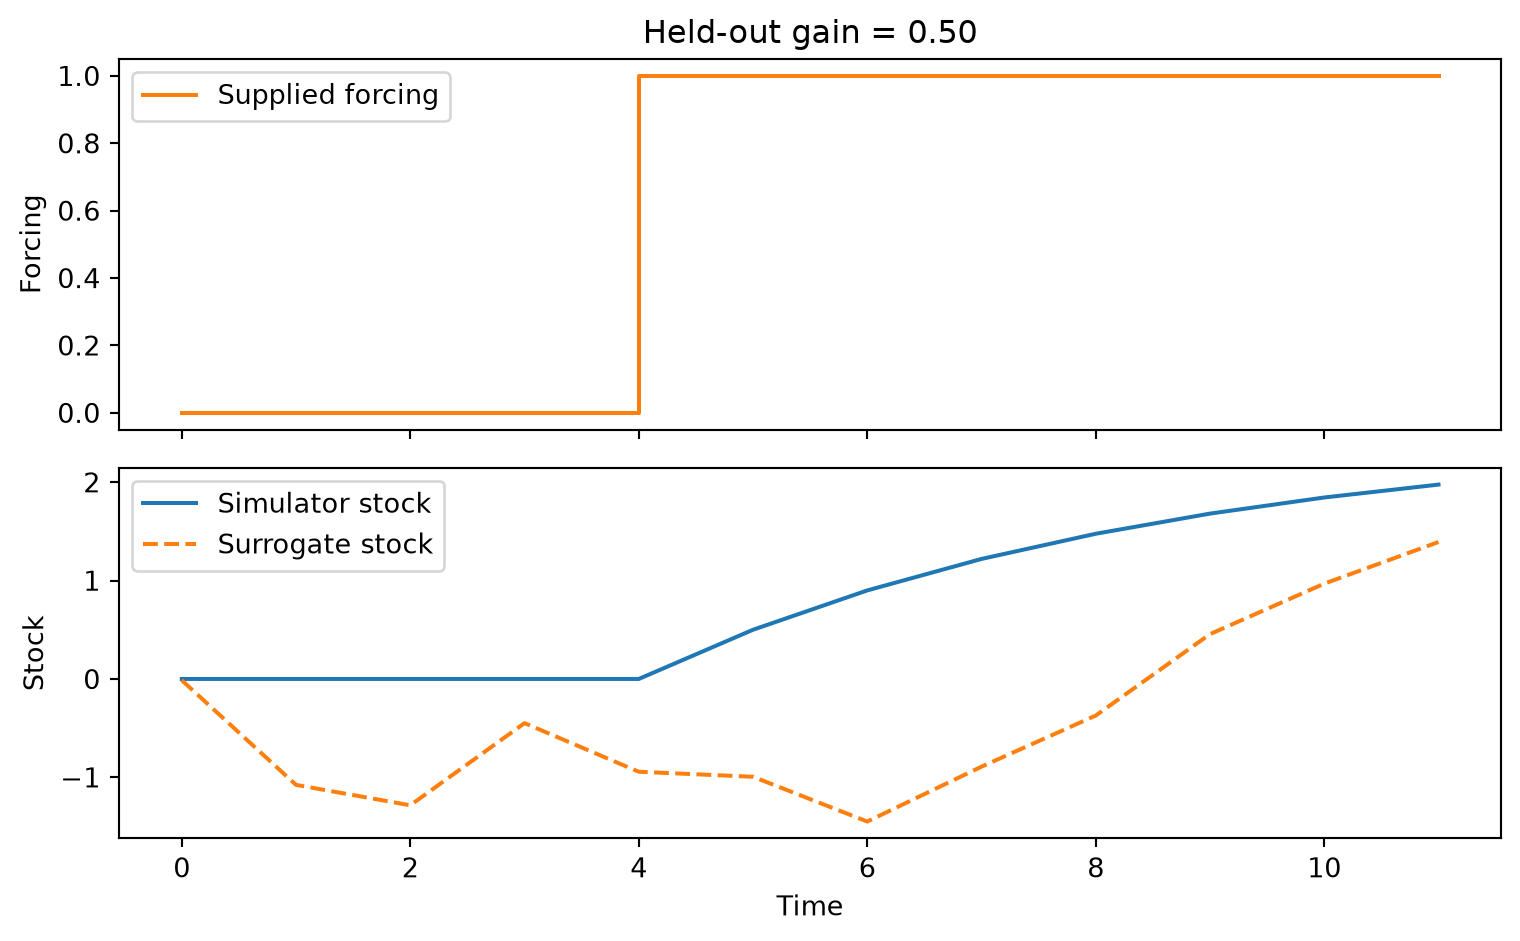

In [4]:
#| label: fig-conditioning-test
#| fig-cap: 'Conditioned transformer fitted to the synthetic gain/schedule training partition: supplied forcing and predicted stock for the first held-out test scenario.'
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axes[0].step(times, known_path[0, :, 0], where="post", color="C1", label="Supplied forcing")
axes[0].set(ylabel="Forcing", title=f"Held-out gain = {query['gain']:.2f}")
axes[0].legend()
axes[1].plot(times, split.test.outputs[i, :, 1], label="Simulator stock")
axes[1].plot(times, prediction[0, :, 0], "--", label="Surrogate stock")
axes[1].set(xlabel="Time", ylabel="Stock")
axes[1].legend()
fig.tight_layout()
plt.show()

*Conditioned transformer fitted to the synthetic gain/schedule training partition: supplied forcing and predicted stock for the first held-out test scenario.*

This short fit misses the initial zero-stock period and accumulates errors during
rollout. The input handling works, but these predictions are not yet faithful
enough to reuse. Check full generated paths, rather than treating a low training
loss as proof of accuracy; see [model comparison](https://ojwatson.github.io/metis/package/model-choice.html).

The transformer uses observed history **strictly before** each predicted time.
Flow matching also supports `observed_outputs`, but can use the entire supplied
path; that is generation conditional on a known schedule, not forecasting from
past observations alone. MLP and iTARFlow do not support sequence conditioning.

The conditioning names and scaling are included when you
[save the model](https://ojwatson.github.io/metis/package/deployment.html). In a real application, only supply quantities
that will actually be known when you make predictions.